In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.decomposition import PCA



In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Penambangan Data/DataSharing/dataset_kredit_nasabah (1).csv')
data.head()

,ID_Nasabah,Usia,Jenis_Kelamin,Pendidikan,Pekerjaan,Pendapatan_Bulanan,Pendapatan_Tahunan,Jumlah_Tanggungan,Jumlah_Pinjaman,Tenor_Bulan,Skor_Kredit,Tanggal_Pengajuan,Status_Pinjaman
0,NSB-001,41,L,S2,Guru,4750000,57000000.0,3.0,51000000.0,36,712.0,2025-09-27,Disetujui
1,NSB-002,42,Laki-laki,s1,PNS,8.9,106800000.0,3.0,160000000.0,60,621.0,05/07/2026,Disetujui
2,NSB-003,41,Laki-laki,S1,Petani,3700000,NaN,1.0,27000000.0,36,640.0,2025-08-09,Disetujui
3,NSB-004,44,Laki-laki,S1,Guru,6400000,76800000.0,3.0,42000000.0,48,704.0,2025-06-01,Disetujui
4,NSB-005,40,Perempuan,S1,Petani,3650000,43800000.0,1.0,59000000.0,24,727.0,2025-02-22,Approved


In [ ]:
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Nasabah          128 non-null    object 
 1   Usia                121 non-null    object 
 2   Jenis_Kelamin       125 non-null    object 
 3   Pendidikan          124 non-null    object 
 4   Pekerjaan           120 non-null    object 
 5   Pendapatan_Bulanan  118 non-null    object 
 6   Pendapatan_Tahunan  123 non-null    float64
 7   Jumlah_Tanggungan   120 non-null    float64
 8   Jumlah_Pinjaman     123 non-null    float64
 9   Tenor_Bulan         128 non-null    object 
 10  Skor_Kredit         120 non-null    float64
 11  Tanggal_Pengajuan   128 non-null    object 
 12  Status_Pinjaman     126 non-null    object 
dtypes: float64(4), object(9)
memory usage: 13.1+ KB


,Pendapatan_Tahunan,Jumlah_Tanggungan,Jumlah_Pinjaman,Skor_Kredit
count,1.230000e+02,120.000000,1.230000e+02,120.000000
mean,9.296098e+07,1.841667,1.375935e+08,640.000000
std,4.871382e+07,2.533791,3.506551e+08,138.481137
min,2.460000e+07,-2.000000,0.000000e+00,-15.000000
25%,5.850000e+07,1.000000,4.600000e+07,570.000000
50%,8.100000e+07,1.000000,7.800000e+07,643.000000
75%,1.140000e+08,3.000000,1.255000e+08,724.750000
max,2.646000e+08,25.000000,3.500000e+09,1250.000000


DATA CLEANSING

Typo

In [ ]:
# Tampilkan nilai unik sebelum perbaikan untuk melihat typos/konsistensi
print("Jenis Kelamin unik:", data['Jenis_Kelamin'].unique())
print("Pendidikan unik:", data['Pendidikan'].unique())

# Lakukan pembersihan: ubah semua teks menjadi huruf kapital (UPPERCASE) dan hilangkan spasi tambahan
for col in ['Jenis_Kelamin', 'Pendidikan', 'Pekerjaan', 'Status_Pinjaman']:
    data[col] = data[col].astype(str).str.upper().str.strip()
    # Kembalikan nilai 'NAN' string ke NaN float yang sesungguhnya
    data[col] = data[col].replace('NAN', np.nan)

print("\nSetelah pembersihan:")
print("Jenis Kelamin unik:", data['Jenis_Kelamin'].unique())
print("Pendidikan unik:", data['Pendidikan'].unique())

Jenis Kelamin unik: ['L' 'Laki-laki' 'Perempuan' '?' 'PEREMPUAN' nan 'Wanita' 'perempuan '
 'laki-laki' 'LAKI-LAKI' 'P']
Pendidikan unik: ['S2' 's1' 'S1' 'Magister' 'SMA' '?' ' SMA' nan '-' 'sma' 'D3' 'SMU'
 'Diploma 3' 's2' 'd3' 'S-1']

Setelah pembersihan:
Jenis Kelamin unik: ['L' 'LAKI-LAKI' 'PEREMPUAN' '?' nan 'WANITA' 'P']
Pendidikan unik: ['S2' 'S1' 'MAGISTER' 'SMA' '?' nan '-' 'D3' 'SMU' 'DIPLOMA 3' 'S-1']


Spasi Berlebih

In [ ]:
# Melakukan strip spasi berlebih hanya pada kolom bertipe data string/object secara aman
for col in data.select_dtypes(include=['object']).columns:
    data[col] = data[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

Nilai Tidak Masuk Akal

In [ ]:
# Bersihkan kolom 'Usia' terlebih dahulu (menghilangkan kata ' tahun') dan ubah ke numerik
data['Usia'] = data['Usia'].astype(str).str.replace(' tahun', '', case=False).str.strip()
data['Usia'] = pd.to_numeric(data['Usia'], errors='coerce')

# Sekarang kita bisa mengecek baris dengan usia yang tidak masuk akal (misalnya <= 0)
print("Data usia tidak masuk akal:")
print(data[data["Usia"] <= 0])

# Opsi 1: Mengganti nilai usia yang tidak valid atau kosong dengan median/mean
# median_usia = data['Usia'].median()
# data['Usia'] = data['Usia'].fillna(median_usia)

Data usia tidak masuk akal:
   ID_Nasabah  Usia Jenis_Kelamin Pendidikan Pekerjaan Pendapatan_Bulanan  \
38    NSB-036 -27.0     PEREMPUAN   MAGISTER    PETANI            6100000   
48    NSB-045   0.0     PEREMPUAN         S1     BURUH            4800000   

    Pendapatan_Tahunan  Jumlah_Tanggungan  Jumlah_Pinjaman Tenor_Bulan  \
38          73200000.0                1.0       38000000.0          24   
48          57600000.0                0.0       53000000.0          36   

    Skor_Kredit Tanggal_Pengajuan Status_Pinjaman  
38        642.0        23/07/2026       DISETUJUI  
48        766.0        28/01/2025       DISETUJUI  


Missing Value

In [ ]:
# Cek jumlah missing value per kolom
data.isnull().sum()

,0
ID_Nasabah,0
Usia,7
Jenis_Kelamin,3
Pendidikan,4
Pekerjaan,8
Pendapatan_Bulanan,10
Pendapatan_Tahunan,5
Jumlah_Tanggungan,8
Jumlah_Pinjaman,5
Tenor_Bulan,0


In [ ]:
# Tampilkan baris yang mengandung missing value
data[data.isnull().any(axis=1)]

,ID_Nasabah,Usia,Jenis_Kelamin,Pendidikan,Pekerjaan,Pendapatan_Bulanan,Pendapatan_Tahunan,Jumlah_Tanggungan,Jumlah_Pinjaman,Tenor_Bulan,Skor_Kredit,Tanggal_Pengajuan,Status_Pinjaman
2,NSB-003,41.0,LAKI-LAKI,S1,PETANI,3700000,NaN,1.0,2.700000e+07,36,640.0,2025-08-09,DISETUJUI
6,NSB-007,42.0,LAKI-LAKI,S1,WIRASWASTA,10700000,128400000.0,NaN,6.000000e+07,12 bulan,554.0,25 April 2026,DITOLAK
7,NSB-050,23.0,PEREMPUAN,S1,PETANI,NaN,52200000.0,4.0,5.200000e+07,48,583.0,28 Februari 2026,DITOLAK
9,NSB-009,28.0,LAKI-LAKI,MAGISTER,PETANI,NaN,68400000.0,1.0,1.150000e+08,12,717.0,28/04/2026,DITOLAK
12,NSB-012,27.0,PEREMPUAN,SMA,WIRASWASTA,NaN,174000000.0,3.0,1.940000e+08,24,601.0,2026-10-04,DISETUJUI
13,NSB-013,NaN,PEREMPUAN,SMA,WIRASWASTA,5800000,69600000.0,2.0,1.030000e+08,48,728.0,2026-10-15,DISETUJUI
18,NSB-063,NaN,?,SMA,PNS,6200000,74400000.0,0.0,2.800000e+07,24 bulan,520.0,15 November 2025,DITOLAK
19,NSB-018,29.0,PEREMPUAN,S1,PETANI,4050000,48600000.0,0.0,4.500000e+07,60,623.0,24 Januari 2026,NaN
24,NSB-023,32.0,PEREMPUAN,NaN,NaN,8650000,103800000.0,3.0,NaN,24,817.0,2026-09-27,DISETUJUI
27,NSB-093,38.0,PEREMPUAN,S1,PROFESIONAL,22050000,264600000.0,NaN,4.760000e+08,48,749.0,2025-04-29,DISETUJUI


<Axes: >

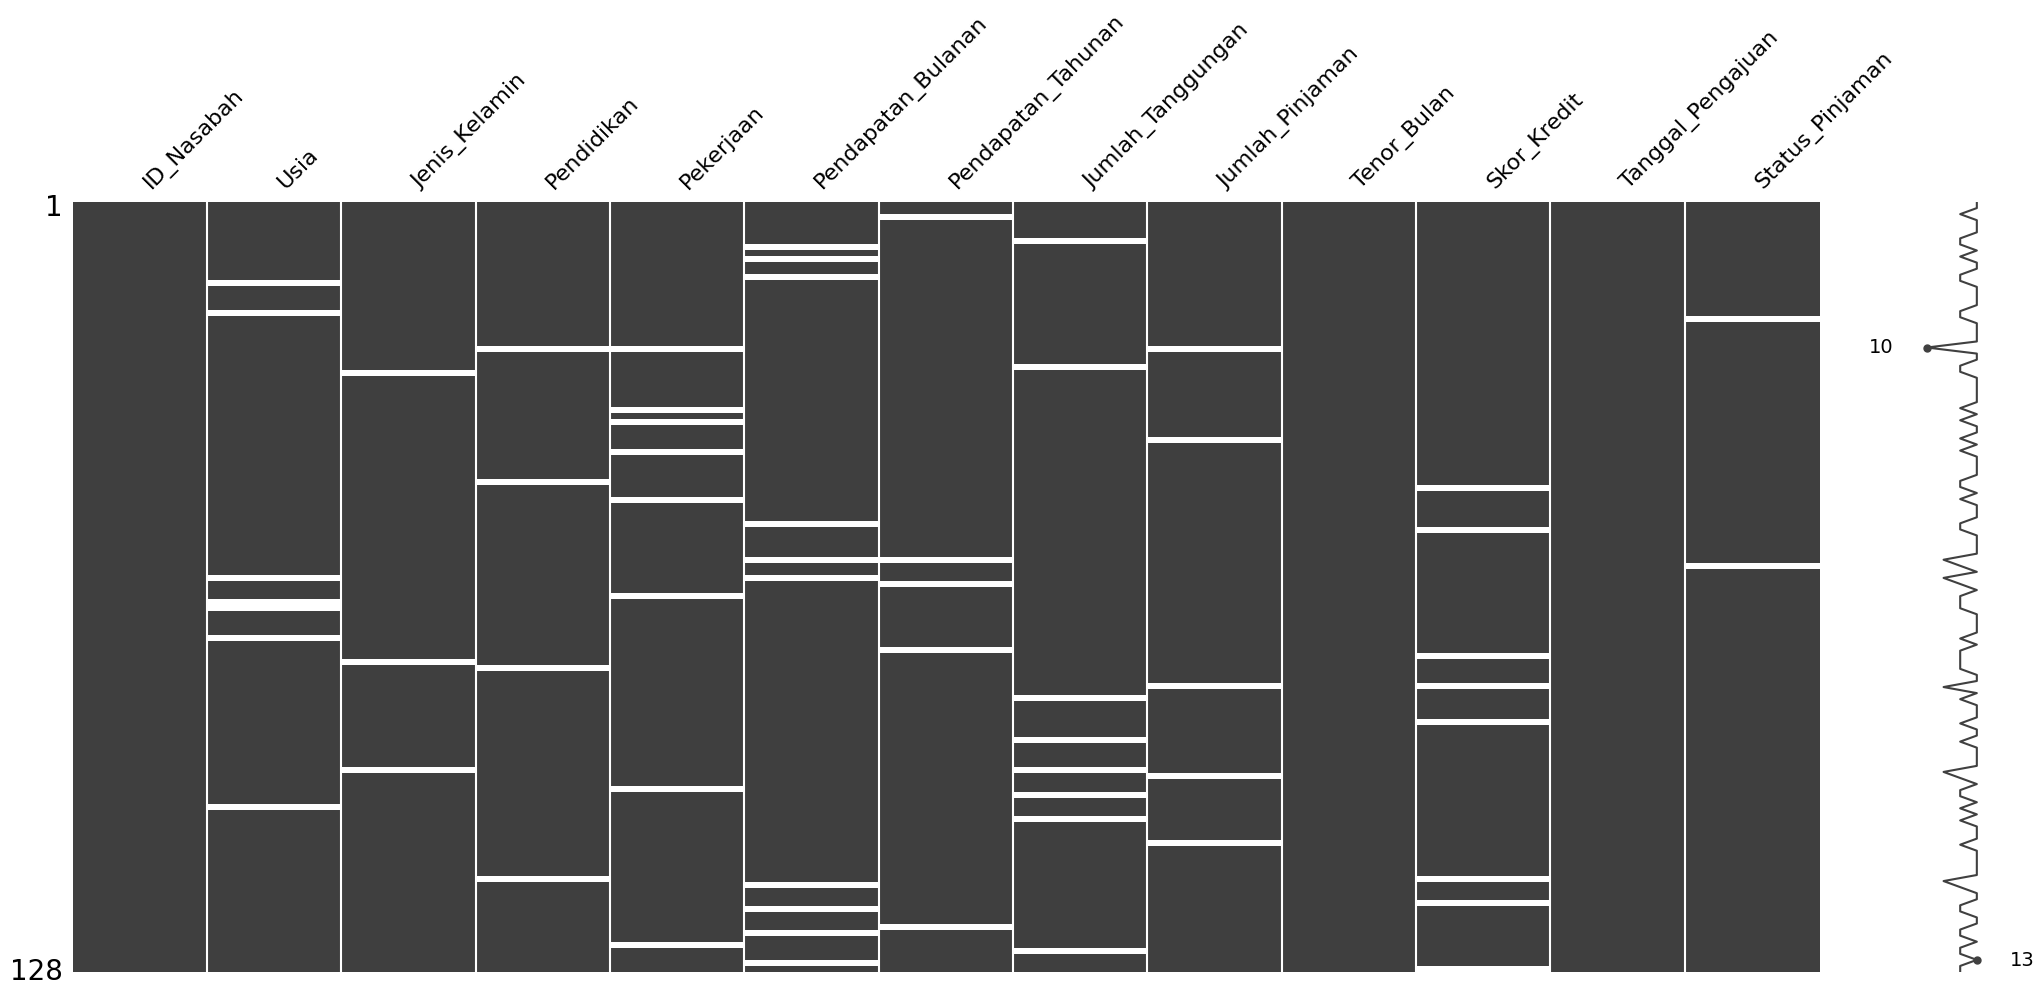

In [ ]:
# Visualisasi pola missing value
msno.matrix(data)

Statistik Deskriptif

In [ ]:
# 1. Imputasi Kolom Numerik menggunakan Median (karena lebih aman terhadap pencilan/outlier)
# Kita perlu membersihkan kolom Pendapatan_Bulanan dahulu karena bertipe 'object'
data['Pendapatan_Bulanan'] = pd.to_numeric(data['Pendapatan_Bulanan'].astype(str).str.replace('.', '', regex=False), errors='coerce')

kolom_numerik = ['Usia', 'Pendapatan_Bulanan', 'Pendapatan_Tahunan', 'Jumlah_Tanggungan', 'Jumlah_Pinjaman', 'Skor_Kredit']
for col in kolom_numerik:
    median_val = data[col].median()
    data[col] = data[col].fillna(median_val)

# 2. Imputasi Kolom Kategori menggunakan Modus (nilai terbanyak)
kolom_kategori = ['Jenis_Kelamin', 'Pendidikan', 'Pekerjaan', 'Status_Pinjaman']
for col in kolom_kategori:
    if data[col].isnull().any():
        modus_val = data[col].mode()[0]
        data[col] = data[col].fillna(modus_val)

# Tampilkan verifikasi jumlah missing value setelah imputasi
print("Jumlah Missing Value Setelah Imputasi:")
print(data.isnull().sum())

Jumlah Missing Value Setelah Imputasi:
ID_Nasabah            0
Usia                  0
Jenis_Kelamin         0
Pendidikan            0
Pekerjaan             0
Pendapatan_Bulanan    0
Pendapatan_Tahunan    0
Jumlah_Tanggungan     0
Jumlah_Pinjaman       0
Tenor_Bulan           0
Skor_Kredit           0
Tanggal_Pengajuan     0
Status_Pinjaman       0
dtype: int64


Outlier

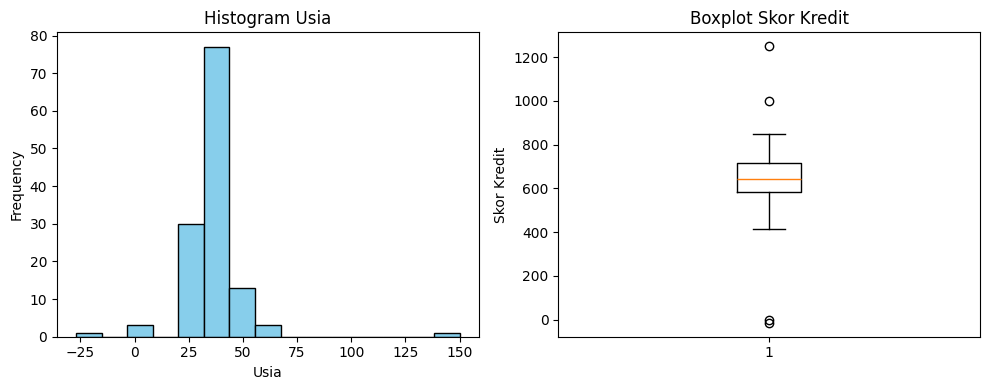

In [ ]:
# Deteksi Outlier dengan Histogram untuk kolom 'Usia'
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(data["Usia"].dropna(), bins=15, color='skyblue', edgecolor='black')
plt.xlabel('Usia')
plt.ylabel('Frequency')
plt.title('Histogram Usia')

# Deteksi Outlier dengan Boxplot untuk kolom 'Skor_Kredit'
plt.subplot(1, 2, 2)
plt.boxplot(data["Skor_Kredit"].dropna())
plt.ylabel('Skor Kredit')
plt.title('Boxplot Skor Kredit')

plt.tight_layout()
plt.show()

DATA TRANSFORMATION

Normalization

In [ ]:
# Inisialisasi MinMaxScaler
scaler = MinMaxScaler()

# Memilih kolom numerik riil dari dataset Anda untuk dinormalisasi
kolom_normalisasi = ['Skor_Kredit', 'Jumlah_Pinjaman', 'Pendapatan_Tahunan']

# Melakukan normalisasi dan menyimpan hasilnya ke kolom baru agar data asli tetap terjaga
for col in kolom_normalisasi:
    data[f'{col}_Normalized'] = scaler.fit_transform(data[[col]])

# Menampilkan hasil beberapa baris awal
data[[col + '_Normalized' for col in kolom_normalisasi]].head()

,Skor_Kredit_Normalized,Jumlah_Pinjaman_Normalized,Pendapatan_Tahunan_Normalized
0,0.574704,0.014571,0.1350
1,0.502767,0.045714,0.3425
2,0.517787,0.007714,0.2350
3,0.568379,0.012000,0.2175
4,0.586561,0.016857,0.0800


Encoding

In [ ]:
# 1. One-Hot Encoding untuk kolom nominal (Jenis_Kelamin)
data = pd.get_dummies(data, columns=['Jenis_Kelamin'], drop_first=True)

# 2. Label Encoding untuk kolom ordinal (Pendidikan)
label_encoder = LabelEncoder()
data['Pendidikan_Encoded'] = label_encoder.fit_transform(data['Pendidikan'])

data[['Pendidikan', 'Pendidikan_Encoded']].head()

,Pendidikan,Pendidikan_Encoded
0,S2,7
1,S1,6
2,S1,6
3,S1,6
4,S1,6


Discretization

In [ ]:
# Mengelompokkan kolom 'Usia' menjadi 3 kategori (Muda, Paruh Baya, Tua)
data['Kategori_Usia'] = pd.cut(data['Usia'], bins=3, labels=['Muda', 'Paruh Baya', 'Tua'])
data[['Usia', 'Kategori_Usia']].head()

,Usia,Kategori_Usia
0,41.0,Paruh Baya
1,42.0,Paruh Baya
2,41.0,Paruh Baya
3,44.0,Paruh Baya
4,40.0,Paruh Baya


Konversi Satuan & Agregasi

In [ ]:
# Mengelompokkan data berdasarkan Pekerjaan dan mencari rata-rata Skor Kredit serta Pendapatan
data_agg = data.groupby('Pekerjaan')[['Skor_Kredit', 'Pendapatan_Tahunan']].mean()
data_agg

,Skor_Kredit,Pendapatan_Tahunan
Pekerjaan,,
?,600.000000,1.335000e+08
BURUH,652.875000,4.605000e+07
GURU,683.470588,6.420000e+07
KARYAWAN SWASTA,679.000000,8.160000e+07
KARYAWAN SWASTA,585.000000,9.722000e+07
P.N.S,670.666667,1.016000e+08
PETANI,638.619048,5.000000e+07
PNS,613.733333,8.916000e+07
PROFESIONAL,684.800000,1.879800e+08


DATA INTEGRATION

In [ ]:
# DATA INTEGRATION (Opsional jika Anda memiliki lebih dari 1 file dataset)
# Kode di bawah ini dinonaktifkan (di-comment) agar tidak memicu error saat 'Run All'

# # Contoh menggabungkan dua dataset berdasarkan kolom ID
# data_lain = pd.read_csv('nama_file_lain.csv')
# data_gabung = pd.merge(data, data_lain, how='left', on='ID_Nasabah')

# # Contoh menambahkan baris baru
# data_append = pd.concat([data, data_baru], ignore_index=True)

print("Data Integration siap dikonfigurasi jika memiliki dataset tambahan.")

Data Integration siap dikonfigurasi jika memiliki dataset tambahan.


FEATURE REDUCTION

In [ ]:
# Menghapus kolom identitas dan tanggal yang tidak relevan untuk analisis statistik/modeling
kolom_dihapus = ['ID_Nasabah', 'Tanggal_Pengajuan']
data = data.drop(columns=[col for col in kolom_dihapus if col in data.columns])
print("Kolom tersisa di dataset:", data.columns.tolist())

Kolom tersisa di dataset: ['Usia', 'Pendidikan', 'Pekerjaan', 'Pendapatan_Bulanan', 'Pendapatan_Tahunan', 'Jumlah_Tanggungan', 'Jumlah_Pinjaman', 'Tenor_Bulan', 'Skor_Kredit', 'Status_Pinjaman', 'Skor_Kredit_Normalized', 'Jumlah_Pinjaman_Normalized', 'Pendapatan_Tahunan_Normalized', 'Jenis_Kelamin_L', 'Jenis_Kelamin_LAKI-LAKI', 'Jenis_Kelamin_P', 'Jenis_Kelamin_PEREMPUAN', 'Jenis_Kelamin_WANITA', 'Pendidikan_Encoded', 'Kategori_Usia']


Feature Extration (PCA)

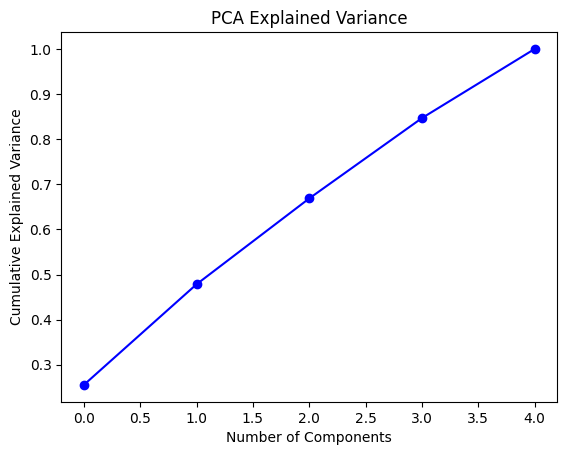

In [ ]:
# Memilih fitur numerik yang sudah dibersihkan
fitur_numerik = ['Usia', 'Pendapatan_Tahunan', 'Jumlah_Tanggungan', 'Jumlah_Pinjaman', 'Skor_Kredit']
x = data[fitur_numerik]

# Standarisasi fitur
x_scaled = StandardScaler().fit_transform(x)

# Cek grafik variansi untuk menentukan jumlah komponen
model = PCA()
results = model.fit(x_scaled)
plt.plot(results.explained_variance_ratio_.cumsum(), '-ob')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance')
plt.show()

Verifikasi & Output Akhir

In [ ]:
# Menampilkan informasi singkat dataset hasil pembersihan dan transformasi
print("=== VERIFIKASI DATASET AKHIR ===")
print(f"Jumlah baris: {data.shape[0]}")
print(f"Jumlah kolom: {data.shape[1]}")
print("\nJumlah missing value terdeteksi:")
print(data.isnull().sum().sum())

# Menyimpan dataset yang bersih ke file CSV baru
data.to_csv('dataset_kredit_cleaned.csv', index=False)
print("\nBerhasil mengekspor dataset dengan nama 'dataset_kredit_cleaned.csv'!")

=== VERIFIKASI DATASET AKHIR ===
Jumlah baris: 128
Jumlah kolom: 20

Jumlah missing value terdeteksi:
0

Berhasil mengekspor dataset dengan nama 'dataset_kredit_cleaned.csv'!
